# 모듈 2: 회수율 예측 모델 학습·평가

- 모듈 1의 산출물(`cleaned_features.csv`)만 읽어서 시작, 모듈 1 코드는 import하지 않음
- feature는 모듈 1에서 이미 확정됨(`base_plus_derived`) — 모듈 2는 모델 종류·하이퍼파라미터만 탐색

In [1]:
import sys
sys.path.append('..')

import pandas as pd
from pathlib import Path

from module2_prediction.config import FEATURE_COLUMNS, TARGET_COLUMNS
from module2_prediction.data_loading import load_cleaned_features, split_by_column
from module2_prediction.modeling import compare_models, MODEL_FACTORIES
from module2_prediction.tuning import tune_models
from module2_prediction.evaluation import evaluate_final_model
from module2_prediction.interpretation import get_feature_importance, compute_shap_values
from module2_prediction.scenario import partial_dependence, predict_blend_scenario

import matplotlib
matplotlib.rcParams['font.family'] = ['Noto Sans CJK JP', 'DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False

CLEANED_DATA_PATH = Path('../data/processed/cleaned_features.csv')
FIGURES_DIR = Path('../module2_prediction/reports/figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 1. 데이터 로드

In [2]:
df = load_cleaned_features(CLEANED_DATA_PATH)
train_df, val_df, test_df = split_by_column(df)
print(f'Train: {len(train_df)}행 / Validation: {len(val_df)}행 / Test: {len(test_df)}행')

Train: 294행 / Validation: 63행 / Test: 63행


## 2. 모델 비교 (기본값, Validation 기준)

RandomForest, XGBoost, LightGBM을 동일한 feature set으로 비교한다. Test는 안 본다.

In [3]:
default_results = compare_models(train_df, val_df)
pd.DataFrame(default_results).T

val_r2  val_rmse   val_mae
RandomForest Ni_회수율_pct  0.750531  2.760271  2.202641
             Co_회수율_pct  0.716820  3.556737  2.733703
XGBoost      Ni_회수율_pct  0.749621  2.765300  2.223076
             Co_회수율_pct  0.708938  3.605900  2.848049
LightGBM     Ni_회수율_pct  0.783451  2.571707  1.996533
             Co_회수율_pct  0.759846  3.275407  2.534324

## 3. 하이퍼파라미터 튜닝 (Validation 기준)

`config.MODEL_HYPERPARAMETER_GRIDS`의 각 조합을 Validation으로 평가해 모델·타겟별 최적값을 고른다.

In [4]:
tuned = tune_models(train_df, val_df)
pd.DataFrame({key: v['metrics'] for key, v in tuned.items()}).T

val_r2  val_rmse   val_mae
RandomForest Ni_회수율_pct  0.755957  2.730087  2.190059
             Co_회수율_pct  0.724480  3.508308  2.691289
XGBoost      Ni_회수율_pct  0.791739  2.522012  2.058859
             Co_회수율_pct  0.800398  2.986095  2.230310
LightGBM     Ni_회수율_pct  0.802450  2.456304  1.991197
             Co_회수율_pct  0.780176  3.133703  2.399097

## 4. 최종 모델 선정 (타겟별 Validation R² 최고 모델)

In [5]:
best_per_target = {
    target: max(
        (key for key in tuned if key[1] == target),
        key=lambda key: tuned[key]['metrics']['val_r2']
    )
    for target in TARGET_COLUMNS
}
for target, (model_name, _) in best_per_target.items():
    p = tuned[(model_name, target)]
    print(f'{target}: {model_name}, params={p["params"]}, val_r2={p["metrics"]["val_r2"]:.4f}')

Ni_회수율_pct: LightGBM, params={'n_estimators': 200, 'max_depth': 2, 'learning_rate': 0.1, 'subsample': 0.8, 'colsample_bytree': 0.8}, val_r2=0.8024
Co_회수율_pct: XGBoost, params={'n_estimators': 200, 'max_depth': 2, 'learning_rate': 0.1, 'subsample': 0.8, 'colsample_bytree': 0.8}, val_r2=0.8004


## 5. 최종 Test 평가 (1회, Train+Validation 재학습)

In [6]:
final_results = {}
for target, (model_name, _) in best_per_target.items():
    params = tuned[(model_name, target)]['params']
    result = evaluate_final_model(
        train_df, val_df, test_df,
        model_name=model_name, model_params=params,
        target_columns=[target],
    )
    final_results[target] = result[target]

pd.DataFrame(final_results).T

,test_r2,test_rmse,test_mae
Ni_회수율_pct,0.870150,1.990582,1.596603
Co_회수율_pct,0.820392,2.844265,2.238856


## 6. Feature Importance / SHAP

최종 선정 모델을 Train+Validation으로 다시 학습해 해석용으로 사용한다.

In [7]:
train_val_df = pd.concat([train_df, val_df], ignore_index=True)

interpretation_models = {}
for target, (model_name, _) in best_per_target.items():
    params = tuned[(model_name, target)]['params']
    model = MODEL_FACTORIES[model_name](**params)
    model.fit(train_val_df[FEATURE_COLUMNS], train_val_df[target])
    interpretation_models[target] = model

    importance = get_feature_importance(model)
    print(f'--- {target} ({model_name}) Feature Importance ---')
    print(importance)

--- Ni_회수율_pct (LightGBM) Feature Importance ---
acid_to_ore_ratio      76
침출온도_C                 72
leach_intensity        64
Cu_불순물_pct             51
Mn_함량_pct              46
침출시간_hr                34
Al_불순물_pct             32
Fe_불순물_pct             31
Li_함량_pct              30
total_impurity_pct     25
target_purity_ratio    23
Ni_함량_pct              22
Co_함량_pct               8
dtype: int32
--- Co_회수율_pct (XGBoost) Feature Importance ---
total_impurity_pct     0.235444
침출온도_C                 0.163229
leach_intensity        0.142025
acid_to_ore_ratio      0.119840
Al_불순물_pct             0.096230
target_purity_ratio    0.065958
Cu_불순물_pct             0.056436
Fe_불순물_pct             0.049112
Co_함량_pct              0.028413
Mn_함량_pct              0.013669
침출시간_hr                0.012520
Li_함량_pct              0.008573
Ni_함량_pct              0.008552
dtype: float32


In [8]:
import shap
import matplotlib.pyplot as plt

target = TARGET_COLUMNS[0]
model = interpretation_models[target]
shap_values = compute_shap_values(model, train_val_df[FEATURE_COLUMNS])
shap.summary_plot(shap_values, train_val_df[FEATURE_COLUMNS], show=False)
plt.savefig(FIGURES_DIR / 'shap_summary.png', bbox_inches='tight')
plt.close()

## 7. 공정조건별 변화 분석 (Partial Dependence)

침출온도_C를 바꿔가며 예측값이 어떻게 변하는지 확인한다 (나머지 변수는 고정).

<Axes: title={'center': 'Ni_회수율_pct vs 침출온도_C'}, xlabel='침출온도_C'>

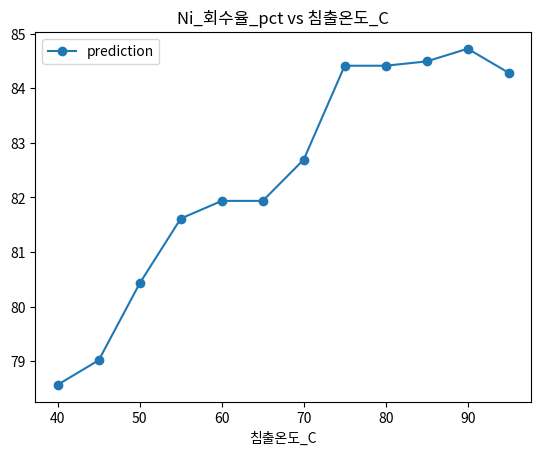

In [9]:
target = TARGET_COLUMNS[0]
model = interpretation_models[target]
base_row = train_val_df.iloc[0]

pd_result = partial_dependence(model, base_row, feature='침출온도_C', values=list(range(40, 96, 5)))
pd_result.plot(x='침출온도_C', y='prediction', marker='o', title=f'{target} vs 침출온도_C')

## 8. 7:3 혼합 시나리오 예측

A급 원료 70% + C급 원료 30%를 혼합했을 때의 예상 Ni 회수율을 예측한다.

In [10]:
target = TARGET_COLUMNS[0]
model = interpretation_models[target]

blend_prediction = predict_blend_scenario(model, train_val_df, grade_a='A', grade_b='C', ratio_a=0.7)
print(f'A:C = 7:3 혼합 예상 {target}: {blend_prediction:.2f}%')

A:C = 7:3 혼합 예상 Ni_회수율_pct: 86.29%


## 9. LSTM 시퀀스 모델 비교 (LSTM-X vs LSTM-X+y)

과거 N개 배치의 흐름으로 다음 배치의 회수율을 예측하는 LSTM. `sequence_modeling.py`는 모듈 1과 위 tabular 모델들(`modeling.py`/`tuning.py`/`evaluation.py`)을 전혀 import하지 않는 독립 모듈이다.

- **LSTM-X**: 과거 공정 feature만 사용
- **LSTM-X+y**: 과거 공정 feature + 과거 실제 회수율까지 사용 (직전 배치의 실제 회수율이 다음 배치 예측 전에 확보된다는 운영 가정 필요)

두 변형을 그리드에서 분리해서 각각 튜닝·평가한다(`tune_sequence_models`의 `grid` 인자로 `include_past_target`을 고정).

In [11]:
from module2_prediction.sequence_modeling import (
    tune_sequence_models,
    evaluate_final_sequence_model,
)

sequence_results = {}
for target in TARGET_COLUMNS:
    tuned = tune_sequence_models(df, feature_columns=FEATURE_COLUMNS, target_columns=[target])
    for variant_name in ['LSTM-X', 'LSTM-X+y']:
        tuned_entry = tuned[(variant_name, target)]
        test_metrics = evaluate_final_sequence_model(
            df, target, tuned_entry['config'], tuned_entry['best_epoch'],
            feature_columns=FEATURE_COLUMNS,
            batch_size=tuned_entry['batch_size'], lr=tuned_entry['lr'],
        )
        sequence_results[(variant_name, target)] = {
            'config': tuned_entry['config'],
            'val_r2': tuned_entry['val_r2'],
            **test_metrics,
        }

pd.DataFrame(sequence_results).T

,,config,val_r2,test_r2,test_rmse,test_mae
LSTM-X,Ni_회수율_pct,"{'window_size': 5, 'hidden_size': 16, 'num_lay...",0.00176,-0.033511,5.615862,4.635369
LSTM-X+y,Ni_회수율_pct,"{'window_size': 5, 'hidden_size': 32, 'num_lay...",0.008083,-0.09234,5.773481,4.810684
LSTM-X,Co_회수율_pct,"{'window_size': 5, 'hidden_size': 32, 'num_lay...",-0.000903,-0.068642,6.937822,5.724143
LSTM-X+y,Co_회수율_pct,"{'window_size': 5, 'hidden_size': 32, 'num_lay...",0.000065,-0.034065,6.824659,5.593522


## 10. 최종 비교: Tabular baseline vs LSTM-X vs LSTM-X+y

단순 성능 순위가 아니라 두 비교축으로 해석한다.

- **LSTM-X vs Tabular baseline** → 시계열 구조 자체의 효과
- **LSTM-X vs LSTM-X+y** → 과거 실제 회수율 정보를 추가했을 때의 효과 (단, LSTM-X+y는 그만큼 더 강한 운영 가정을 요구한다)

In [12]:
comparison = {}
for target in TARGET_COLUMNS:
    comparison[('Tabular-best', target)] = final_results[target]
    for variant_name in ['LSTM-X', 'LSTM-X+y']:
        comparison[(variant_name, target)] = {
            k: v for k, v in sequence_results[(variant_name, target)].items() if k != 'config'
        }

pd.DataFrame(comparison).T

,,test_r2,test_rmse,test_mae,val_r2
Tabular-best,Ni_회수율_pct,0.870150,1.990582,1.596603,NaN
LSTM-X,Ni_회수율_pct,-0.033511,5.615862,4.635369,0.001760
LSTM-X+y,Ni_회수율_pct,-0.092340,5.773481,4.810684,0.008083
Tabular-best,Co_회수율_pct,0.820392,2.844265,2.238856,NaN
LSTM-X,Co_회수율_pct,-0.068642,6.937822,5.724143,-0.000903
LSTM-X+y,Co_회수율_pct,-0.034065,6.824659,5.593522,0.000065
